# Pertemuan 10 — Diagnostik Model Runtun Waktu
## Notebook Praktikum · Analisis Runtun Waktu (SDT-3329)

**Program Studi Sains Data · Fakultas Digital, Desain dan Bisnis · Institut Teknologi Sains Bandung**
Semester 6 · 3 SKS (T: 2, P: 1) · Mata kuliah syarat: Statistika Komputasi, Pemrograman Statistika, Aljabar Linear ·
Dosen pengampu: Bakti Siregar, S.Si., M.Sc

---

### Keselarasan dengan RPS (OBE)

| Komponen | Isi |
|---|---|
| **Kemampuan akhir (Sub-CPMK)** | Mahasiswa mampu melakukan diagnostik residual dan mengidentifikasi area perbaikan model runtun waktu. |
| **CPL / CPMK** | CPL-1 · CPL-2 · CPL-3 · CPMK-4 |
| **Indikator** | Mampu menganalisis residual model (plot, uji statistik) dan mengusulkan perbaikan jika asumsi tidak terpenuhi. |
| **Kriteria penilaian** | Ketepatan analisis residual dan relevansi rekomendasi perbaikan. |
| **Materi pembelajaran** | Plot residual, uji kenormalan, uji autokorelasi Ljung-Box; mengidentifikasi masalah model; strategi perbaikan. |
| **Konsep pemrograman** | Fungsi diagnostik yang mengembalikan laporan terstruktur + aturan keputusan; menguji sebuah uji dengan Monte Carlo (bagian 🧠) |
| **Bobot penilaian minggu ini** | 3% |
| **Alokasi waktu** | TM 2 × 50′ · Praktikum 1 × 170′ · PT 2 × 60′ · BM 2 × 60′ |
| **Keterkaitan tugas (RTM)** | — (pendalaman diagnostik Tugas 2) |
| **Pustaka** | Hyndman & Athanasopoulos (2021) Bab 5.4; Cryer & Chan (2008) Bab 8 |

**Dataset:** Airline Passengers · Penjualan mobil Quebec · Debit Sungai Nil (perubahan level 1898) · deret simulasi
**Pustaka Python:** pandas · NumPy · Matplotlib · seaborn · statsmodels · SciPy

### Peta notebook

| Bagian | Isi | Indikator RPS |
|---|---|---|
| 1 | Sifat residu yang baik dan mengapa masing-masing penting | Menganalisis residual model |
| 2 | Perangkat diagnostik: plot residu, ACF, Q-Q, Ljung-Box, Jarque–Bera, ARCH-LM | Plot residual & uji statistik |
| 3 | Tiga model Airline: dua salah spesifikasi, satu tepat — membaca gejalanya | **Mengidentifikasi masalah model** |
| 4 | Fungsi diagnostik dengan aturan keputusan dan rekomendasi perbaikan | **Relevansi rekomendasi perbaikan** |
| 5 | Strategi perbaikan: outlier & perubahan level dengan variabel intervensi | Strategi perbaikan model |
| 6 | 🧠 Konsep pemrograman: menguji sebuah uji dengan Monte Carlo (koreksi derajat bebas Ljung-Box) | — |
| 7 | Latihan, ringkasan, logbook | — |

### Cara menggunakan notebook ini

- Jalankan sel berurutan (Google Colab atau Jupyter lokal). Di Colab, `statsmodels` sudah tersedia; `arch` (P11) dipasang dengan `pip install arch`.
- Sel **LATIHAN** berisi `TODO`; lengkapi selama praktikum. Bagian 🧠 **Konsep Pemrograman** menjelaskan prinsip di balik kode,
  bukan sekadar cara memanggil pustaka.
- Penilaian memakai rubrik RPS — *Kualitas Implementasi (Kode & Model)* dan *Interpretasi & Visualisasi Hasil* — serta
  Rubrik PRAKTIKUM (eksekusi 40%, pembersihan data 35%, penanganan error & modularitas 25%).
- Unggah notebook dan logbook ke LMS/Virtual Lab setelah praktikum.

---
## 0. Persiapan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'figure.figsize': (10, 3.4)})
pd.set_option('display.width', 140)
RANDOM_STATE = 42
from dataclasses import dataclass, field
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from statsmodels.graphics.tsaplots import plot_acf
from scipy import stats
air = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv', parse_dates=['Month'], index_col='Month')['Passengers'].asfreq('MS')
nil = sm.datasets.nile.load_pandas().data
nil = pd.Series(nil.volume.values, index=pd.date_range('1871', periods=len(nil), freq='YS'), name='debit')

---
## 1. Residu yang Baik

Residu $e_t = y_t - \hat y_{t|t-1}$ (galat ramalan satu langkah) dari model yang memadai seharusnya:

| Sifat | Bila dilanggar | Seberapa serius |
|---|---|---|
| **Tidak berautokorelasi** | Masih ada pola yang dapat dimodelkan → ramalan tidak efisien | **Wajib** — model perlu diperbaiki |
| **Rata-rata nol** | Ramalan bias | **Wajib** — tambahkan konstanta/drift |
| Varians konstan (homoskedastis) | Interval prediksi salah lebar | Penting untuk interval — transformasi log/Box-Cox atau GARCH (P11) |
| Berdistribusi normal | Interval berbasis normal kurang tepat | Paling ringan — gunakan interval bootstrap |

Residu yang lolos semua uji **tidak menjamin** model terbaik untuk meramal (P7: HW mengalahkan SARIMA meski residu SARIMA baik),
tetapi residu yang gagal **menjamin** ada informasi yang belum dimanfaatkan.

---
## 2. Perangkat Diagnostik

| Uji | H₀ | Catatan |
|---|---|---|
| **Ljung-Box** | Tidak ada autokorelasi hingga lag h | Untuk residu ARMA(p,q), derajat bebas = h − p − q (`model_df`) |
| **Jarque–Bera** | Residu normal (skewness 0, kurtosis 3) | Peka pada sampel besar |
| **ARCH-LM** (Engle) | Tidak ada heteroskedastisitas bersyarat | Bila ditolak → volatilitas berkelompok → GARCH |
| Uji heteroskedastisitas statsmodels | Varians paruh awal = paruh akhir | Mendeteksi varians yang berubah sepanjang waktu |

---
## 3. Tiga Model Airline

| Model | Spesifikasi |
|---|---|
| A | ARIMA(1,1,1) pada log — **tanpa** komponen musiman |
| B | SARIMA(0,1,1)(0,1,1)₁₂ pada data **asli** (tanpa log) |
| C | SARIMA(0,1,1)(0,1,1)₁₂ pada **log** (model airline) |

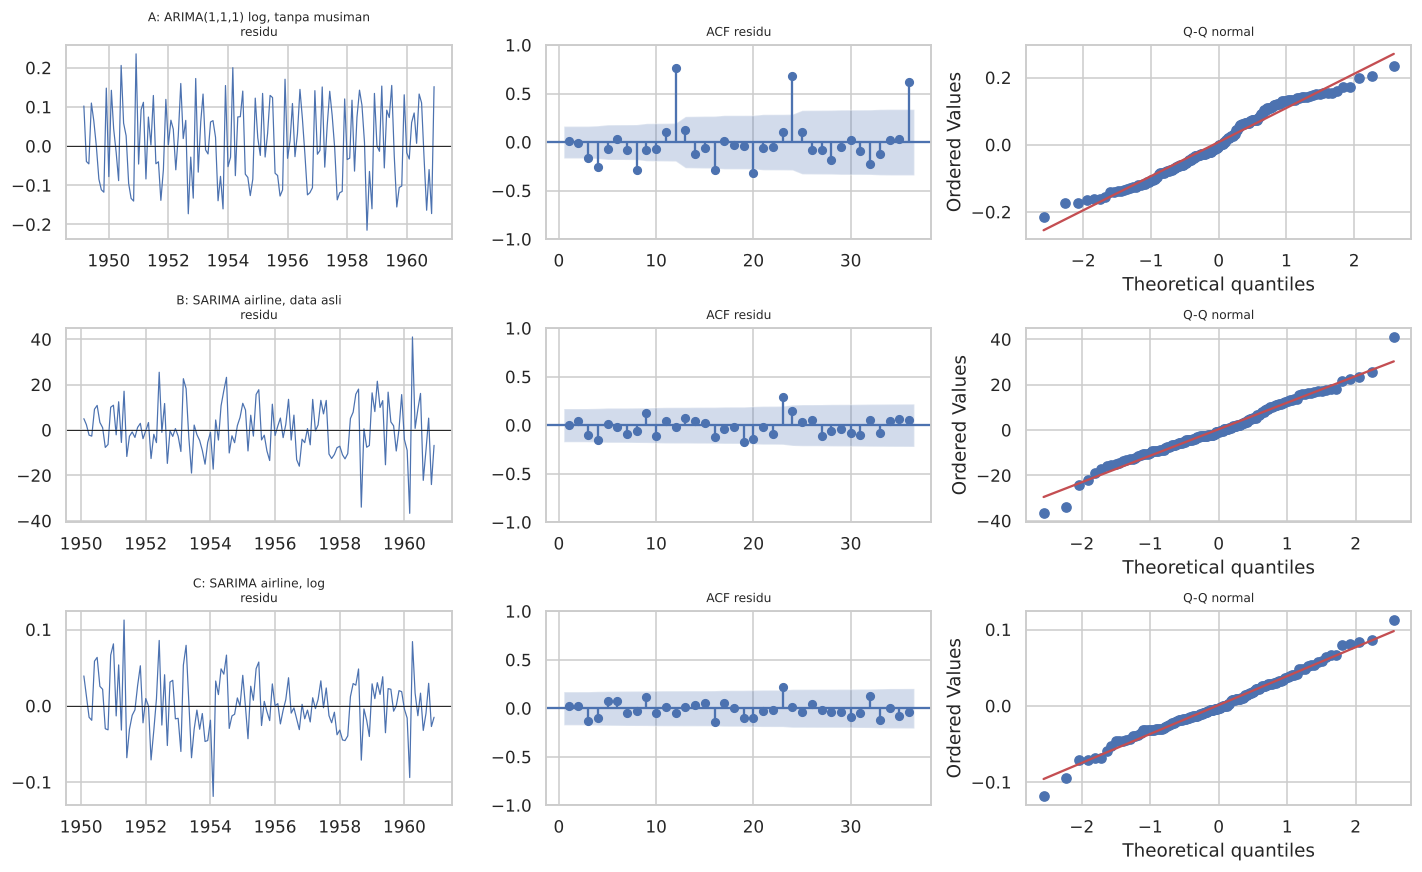

In [ ]:
model = {
    'A: ARIMA(1,1,1) log, tanpa musiman': (SARIMAX(np.log(air), order=(1, 1, 1)).fit(disp=False), 2, 2),
    'B: SARIMA airline, data asli': (SARIMAX(air, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False), 2, 13),
    'C: SARIMA airline, log': (SARIMAX(np.log(air), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False), 2, 13),
}
fig, axs = plt.subplots(3, 3, figsize=(13, 8))
for i, (nama, (m, k, buang)) in enumerate(model.items()):
    r = m.resid.iloc[buang:]
    axs[i, 0].plot(r, lw=.8); axs[i, 0].axhline(0, c='k', lw=.6); axs[i, 0].set_title(f'{nama}\nresidu', fontsize=8)
    plot_acf(r, lags=36, ax=axs[i, 1], zero=False, title='ACF residu'); axs[i, 1].title.set_fontsize(8)
    stats.probplot(r, plot=axs[i, 2]); axs[i, 2].set_title('Q-Q normal', fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
def ringkas_uji(r, model_df, lag=24):
    lb = acorr_ljungbox(r, lags=[lag], model_df=model_df).lb_pvalue.iloc[0]
    jb = jarque_bera(r)[1]
    arch = het_arch(r, nlags=12)[1]
    h = len(r) // 2; rasio_var = r.iloc[h:].var() / r.iloc[:h].var()
    return {'Ljung-Box p (lag 24)': lb, 'Jarque-Bera p': jb, 'ARCH-LM p': arch, 'rasio varians paruh 2/1': rasio_var,
            'ACF lag 12': r.autocorr(12)}
print(pd.DataFrame({nama: ringkas_uji(m.resid.iloc[buang:], k) for nama, (m, k, buang) in model.items()}).T.round(4))

                                    Ljung-Box p (lag 24)  Jarque-Bera p  ARCH-LM p  rasio varians paruh 2/1  ACF lag 12
A: ARIMA(1,1,1) log, tanpa musiman                0.0000         0.0486     0.0003                   1.0302      0.8327
B: SARIMA airline, data asli                      0.0083         0.0527     0.2731                   1.8562     -0.0268
C: SARIMA airline, log                            0.3676         0.4140     0.2312                   0.4478     -0.0586


> **Membaca gejala:**
> - **Model A** — ACF residu lag 12 = 0,83 dan Ljung-Box menolak keras → pola **musiman** belum dimodelkan.
>   Perbaikan: komponen musiman (D = 1, SMA/SAR).
> - **Model B** — autokorelasi musiman sudah hilang (ACF lag 12 ≈ 0), tetapi Ljung-Box **masih menolak** (p ≈ 0,008) dan
>   varians paruh kedua ±1,9 kali paruh pertama: pola multiplikatif yang dipaksa aditif meninggalkan struktur dan
>   heteroskedastisitas. Perbaikan yang tepat adalah **log** (model C), bukan menambah orde.
> - **Model C** — Ljung-Box, Jarque–Bera, ARCH-LM semuanya tidak menolak → **memadai**. Rasio varians 0,45 menunjukkan log
>   sedikit "terlalu kuat": variasi relatif tahun-tahun awal lebih besar. Ini konsisten dengan P2, di mana λ Box-Cox optimal
>   adalah 0,15, bukan 0.

---
## 4. Fungsi Diagnostik dengan Aturan Keputusan

Diagnostik yang baik berakhir dengan **tindakan**. Fungsi berikut mengubah hasil uji menjadi rekomendasi, sehingga dapat dipakai
ulang untuk Tugas 2 dan proyek.

In [ ]:
@dataclass
class LaporanDiagnostik:
    n: int
    uji: dict
    masalah: list = field(default_factory=list)
    rekomendasi: list = field(default_factory=list)

    @property
    def memadai(self):
        return not any(m.startswith('WAJIB') for m in self.masalah)

    def __str__(self):
        baris = [f'n = {self.n} | memadai: {"YA" if self.memadai else "TIDAK"}']
        baris += [f'  ✗ {m}' for m in self.masalah] or ['  ✓ tidak ada masalah terdeteksi']
        baris += [f'  → {r}' for r in self.rekomendasi]
        return '\n'.join(baris)

def diagnostik(resid, model_df=0, m=12, alpha=0.05):
    """Diagnostik residu + aturan keputusan. resid: Series residu (tanpa periode awal yang tidak informatif)."""
    r = pd.Series(resid).dropna()
    if len(r) < 3 * m:
        raise ValueError('residu terlalu sedikit untuk diagnostik yang andal')
    u = ringkas_uji(r, model_df, lag=min(2 * m, len(r) // 4))
    u['t-test rata-rata p'] = stats.ttest_1samp(r, 0).pvalue
    lap = LaporanDiagnostik(len(r), {k: round(v, 4) for k, v in u.items()})
    batas = 1.96 / np.sqrt(len(r))
    if u['Ljung-Box p (lag 24)'] < alpha:
        if abs(r.autocorr(m)) > batas:
            lap.masalah.append(f'WAJIB: autokorelasi musiman (ACF lag {m} = {r.autocorr(m):.2f})')
            lap.rekomendasi.append('tambahkan differencing musiman (D=1) atau komponen SAR/SMA')
        else:
            lap.masalah.append('WAJIB: autokorelasi pada lag biasa')
            lap.rekomendasi.append('naikkan orde p atau q; periksa ACF/PACF residu')
    if u['t-test rata-rata p'] < alpha:
        lap.masalah.append('WAJIB: rata-rata residu tidak nol (ramalan bias)')
        lap.rekomendasi.append('tambahkan konstanta/drift atau periksa differencing')
    rv = u['rasio varians paruh 2/1']
    if rv > 2:
        lap.masalah.append(f'varians membesar sepanjang waktu (rasio {rv:.2f})')
        lap.rekomendasi.append('transformasi log/Box-Cox sebelum pemodelan')
    elif rv < 0.5:
        lap.masalah.append(f'varians mengecil sepanjang waktu (rasio {rv:.2f})')
        lap.rekomendasi.append('transformasi mungkin terlalu kuat (coba Box-Cox λ > 0) atau ada perubahan struktural; untuk ramalan, beri bobot lebih pada data terbaru')
    if u['ARCH-LM p'] < alpha:
        lap.masalah.append('heteroskedastisitas bersyarat (volatilitas berkelompok)')
        lap.rekomendasi.append('pertimbangkan model GARCH untuk varians (P11)')
    if u['Jarque-Bera p'] < alpha:
        lap.masalah.append('residu tidak normal')
        lap.rekomendasi.append('gunakan interval prediksi bootstrap; periksa outlier (Bagian 5)')
    return lap

for nama, (mdl, k, buang) in model.items():
    print(nama); print(diagnostik(mdl.resid.iloc[buang:], model_df=k)); print()

A: ARIMA(1,1,1) log, tanpa musiman
n = 142 | memadai: TIDAK
  ✗ WAJIB: autokorelasi musiman (ACF lag 12 = 0.83)
  ✗ heteroskedastisitas bersyarat (volatilitas berkelompok)
  ✗ residu tidak normal
  → tambahkan differencing musiman (D=1) atau komponen SAR/SMA
  → pertimbangkan model GARCH untuk varians (P11)
  → gunakan interval prediksi bootstrap; periksa outlier (Bagian 5)

B: SARIMA airline, data asli
n = 131 | memadai: TIDAK
  ✗ WAJIB: autokorelasi pada lag biasa
  → naikkan orde p atau q; periksa ACF/PACF residu

C: SARIMA airline, log
n = 131 | memadai: YA
  ✗ varians mengecil sepanjang waktu (rasio 0.45)
  → transformasi mungkin terlalu kuat (coba Box-Cox λ > 0) atau ada perubahan struktural; untuk ramalan, beri bobot lebih pada data terbaru



> Aturan otomatis bekerja baik untuk model A dan C, tetapi untuk model B ia menyarankan "naikkan orde p atau q" — padahal akar
> masalahnya adalah transformasi (ambang rasio varians 2 tidak terlampaui karena rasionya 1,86). Fungsi diagnostik membantu
> menyusun daftar periksa; **penilaian analis** tetap menentukan perbaikan yang benar.

---
## 5. Strategi Perbaikan: Outlier dan Perubahan Level

Peristiwa luar biasa (bencana, kebijakan, pembangunan bendungan) meninggalkan jejak pada residu. Analisis intervensi menambahkan
**variabel dummy** sebagai regresor eksogen (`exog`) di SARIMAX:

| Jenis intervensi | Dummy | Contoh |
|---|---|---|
| Outlier aditif (pulsa) | 1 pada satu waktu, 0 lainnya | Pemogokan satu bulan |
| Perubahan level (*step*) | 0 sebelum, 1 sesudah | Bendungan, regulasi baru |

n = 100 | memadai: YA
  ✗ varians mengecil sepanjang waktu (rasio 0.45)
  → transformasi mungkin terlalu kuat (coba Box-Cox λ > 0) atau ada perubahan struktural; untuk ramalan, beri bobot lebih pada data terbaru

Residu terstandar terbesar: {Timestamp('1913-01-01 00:00:00'): 2.72, Timestamp('1916-01-01 00:00:00'): 2.45, Timestamp('1879-01-01 00:00:00'): 2.26}

Dengan dummy perubahan level 1899: efek = -247.9 (p = 0.0000)
AIC tanpa intervensi 1282.1 -> dengan intervensi 1259.0
Parameter tanpa intervensi: {'const': 919.351, 'ar.L1': 0.861, 'ma.L1': -0.518, 'sigma2': 19807.049}
Parameter dengan intervensi: {'const': 1097.698, 'bendungan': -247.904, 'ar.L1': 0.036, 'ma.L1': 0.127, 'sigma2': 15549.942}


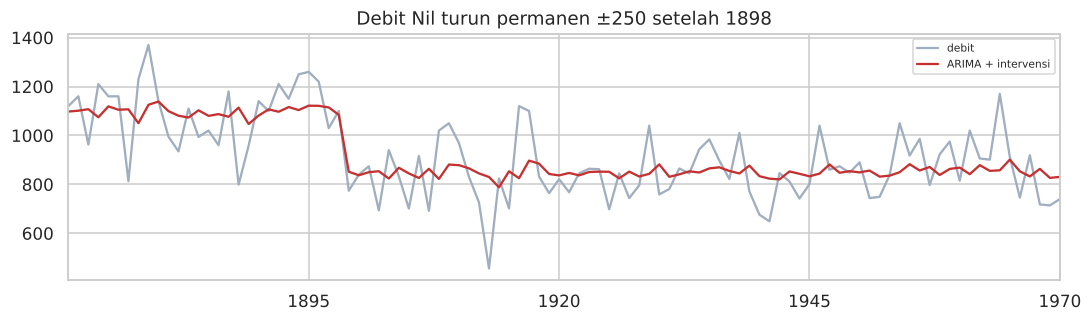

In [ ]:
m0 = ARIMA(nil, order=(1, 0, 1)).fit()
r0 = m0.resid
print(diagnostik(r0, model_df=2, m=10))
z = (r0 - r0.mean()) / r0.std()
print('\nResidu terstandar terbesar:', z.abs().nlargest(3).round(2).to_dict())

langkah = pd.Series((nil.index.year >= 1899).astype(float), index=nil.index, name='bendungan')
m1 = ARIMA(nil, exog=langkah, order=(1, 0, 1)).fit()
print(f"\nDengan dummy perubahan level 1899: efek = {m1.params['bendungan']:.1f} (p = {m1.pvalues['bendungan']:.4f})")
print(f'AIC tanpa intervensi {m0.aic:.1f} -> dengan intervensi {m1.aic:.1f}')
print('Parameter tanpa intervensi:', m0.params.round(3).to_dict())
print('Parameter dengan intervensi:', m1.params.round(3).to_dict())
fig, ax = plt.subplots(figsize=(10, 3))
nil.plot(ax=ax, color='#a0aec0'); (m1.fittedvalues).plot(ax=ax, color='#c53030', label='ARIMA + intervensi')
ax.legend(fontsize=7); ax.set_title('Debit Nil turun permanen ±250 setelah 1898'); plt.tight_layout(); plt.show()

> Menariknya, model tanpa intervensi **lolos** diagnostik autokorelasi — ia "menjelaskan" pergeseran level dengan koefisien AR
> yang tinggi (φ = 0,86), seolah-olah deret sangat persisten. Rasio varians 0,45 adalah satu-satunya petunjuk adanya perubahan
> struktural. Dengan dummy perubahan level, efek bendungan diestimasi langsung (≈ −248 unit, sangat signifikan), AIC turun dari
> 1282 ke 1259, dan φ anjlok ke 0,04: debit Nil ternyata hampir tidak persisten setelah pergeseran dimodelkan dengan benar. **Memahami domain** (ada peristiwa apa?) sering menghasilkan perbaikan yang tidak dapat
> ditemukan dari statistik saja.

### Ringkasan strategi perbaikan

| Gejala | Perbaikan |
|---|---|
| Autokorelasi di lag biasa | Naikkan p/q; periksa differencing |
| Autokorelasi di lag musiman | D = 1, tambah SAR/SMA |
| Rata-rata residu ≠ 0 | Konstanta/drift |
| Varians membesar dengan level | Log / Box-Cox |
| Volatilitas berkelompok (ARCH-LM) | GARCH (P11) |
| Residu ekstrem terisolasi / pergeseran | Dummy intervensi, cari penyebabnya |
| Non-normal | Interval bootstrap |

---
## 6. 🧠 Konsep Pemrograman — Menguji Sebuah Uji dengan Monte Carlo

Mengapa Ljung-Box untuk residu ARMA(p,q) memakai derajat bebas h − p − q? Kita **membuktikannya** dengan simulasi: bangkitkan
ribuan deret dari ARMA(1,1) yang diketahui, estimasi model yang **benar**, lalu hitung seberapa sering Ljung-Box menolak. Karena
modelnya benar, tingkat tolak seharusnya ±5%.

In [ ]:
def tingkat_tolak_lb(R=300, n=150, lag=10, seed0=0):
    tanpa, dengan = 0, 0
    for i in range(R):
        y = ArmaProcess([1, -0.7], [1, 0.4]).generate_sample(n, distrvs=np.random.default_rng(seed0 + i).standard_normal)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            r = ARIMA(y, order=(1, 0, 1)).fit().resid
        tanpa += acorr_ljungbox(r, lags=[lag], model_df=0).lb_pvalue.iloc[0] < 0.05
        dengan += acorr_ljungbox(r, lags=[lag], model_df=2).lb_pvalue.iloc[0] < 0.05
    return tanpa / R, dengan / R

import time; t0 = time.time()
a, b = tingkat_tolak_lb()
print(f'Model BENAR ARMA(1,1), Ljung-Box lag 10, 300 replikasi ({time.time()-t0:.0f} dtk):')
print(f'  tanpa koreksi (df = 10)   -> menolak {a:.1%}')
print(f'  dengan koreksi (df = 10-2) -> menolak {b:.1%}   (target 5%)')

Model BENAR ARMA(1,1), Ljung-Box lag 10, 300 replikasi (7 dtk):
  tanpa koreksi (df = 10)   -> menolak 2.7%
  dengan koreksi (df = 10-2) -> menolak 5.3%   (target 5%)


> Tanpa koreksi, Ljung-Box **terlalu jarang** menolak: parameter yang diestimasi sudah "menyerap" sebagian autokorelasi
> sehingga residu tampak lebih acak dari seharusnya, dan uji kehilangan kuasa. Koreksi `model_df = p + q` mengembalikan tingkat
> tolak mendekati 5%. Pelajaran pemrograman: prosedur statistik juga perangkat lunak — sifatnya dapat (dan perlu) **diverifikasi
> dengan simulasi** sebelum dipercaya. `LaporanDiagnostik` memakai `dataclass` dengan `property` (`memadai`) dan `__str__`
> sehingga hasilnya terstruktur, dapat diuji dengan `assert`, dan tetap enak dibaca.

In [ ]:
# Uji unit untuk fungsi diagnostik: residu white noise harus dinyatakan memadai, residu berpola musiman tidak
wn = pd.Series(np.random.default_rng(1).normal(size=200))
musiman = wn + 2 * np.sin(2 * np.pi * np.arange(200) / 12)
assert diagnostik(wn).memadai, 'white noise seharusnya memadai'
assert not diagnostik(musiman).memadai, 'pola musiman seharusnya terdeteksi'
print('Uji unit fungsi diagnostik lulus ✓')

Uji unit fungsi diagnostik lulus ✓


---
## 7. Latihan

### LATIHAN 1 — Tugas 2, langkah 6
Jalankan `diagnostik()` pada residu model terbaik Tugas 2 Anda. Bila tidak memadai, terapkan rekomendasinya dan bandingkan diagnostik
serta akurasi sebelum/sesudah perbaikan.

In [ ]:
# TODO

### LATIHAN 2 — Penjualan mobil
Diagnosis residu Holt-Winters aditif dan SARIMA airline pada penjualan mobil Quebec (P5, P7). Model mana yang residunya lebih baik?
Apakah itu sama dengan model yang lebih akurat?

In [ ]:
# TODO

### LATIHAN 3 — Outlier aditif
Sisipkan outlier (+40%) pada Airline bulan Maret 1955. Tunjukkan dampaknya pada residu dan parameter SARIMA, lalu perbaiki dengan dummy
pulsa. Bandingkan ramalan 12 bulan sebelum dan sesudah perbaikan.

In [ ]:
# TODO

---
## 8. Ringkasan Pertemuan 10

- ▸ Residu yang baik: tanpa autokorelasi dan rata-rata nol (wajib); varians konstan dan normal (untuk interval).
- ▸ Gunakan plot residu, ACF residu, Q-Q plot, Ljung-Box (`model_df = p + q`), Jarque–Bera, ARCH-LM.
- ▸ Gejala menunjuk perbaikan: musiman tersisa → SARIMA; varians melebar → log; volatilitas berkelompok → GARCH; pergeseran → intervensi.
- ▸ Bungkus diagnostik menjadi fungsi dengan aturan keputusan; verifikasi prosedur statistik dengan simulasi.

### Tugas mandiri (PT & BM)
Lengkapi bagian diagnostik Tugas 2. Mulai cari dataset kompleks untuk Tugas 3 (keuangan / makroekonomi / sensor).

**Pertemuan berikutnya:** `P11_ARCH_GARCH.ipynb`

---
## Logbook Praktikum — Pertemuan 10

Salin sel di bawah, isi, lalu unggah bersama notebook ke LMS/Virtual Lab (aktivitas PT & BM sesuai RPS).

In [ ]:
logbook = {
    'Nama / NIM'                          : 'TODO',
    'Pertemuan'                           : 10,
    'Tanggal praktikum'                   : 'TODO',
    'Tiga temuan terpenting (dengan angka)': ['TODO', 'TODO', 'TODO'],
    'Galat yang ditemui & cara mengatasi' : 'TODO',
    'Latihan yang diselesaikan'           : 'TODO',
    'Pertanyaan untuk pertemuan berikutnya': 'TODO',
}
for k, v in logbook.items():
    print(f'{k:<38}: {v}')

Nama / NIM                            : TODO
Pertemuan                             : 10
Tanggal praktikum                     : TODO
Tiga temuan terpenting (dengan angka) : ['TODO', 'TODO', 'TODO']
Galat yang ditemui & cara mengatasi   : TODO
Latihan yang diselesaikan             : TODO
Pertanyaan untuk pertemuan berikutnya : TODO
